# Penalty sweep demo

Refit one target across a **penalty grid** (same cells each time), then **filter factors** by stability across the path (sign flips / going to zero). `frac_zero` is an L1/elastic concept -- ridge never zeros.

## 1. Load

In [1]:
import sys
from pathlib import Path

_root = next(p for p in Path.cwd().resolve().parents if (p / '.git').exists() or (p / 'setup.py').exists())
for _p in (str(_root), str(_root / 'src')):
    if _p not in sys.path:
        sys.path.insert(0, _p)

import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
from metab_processing.LinearRegression import signature_helpers as sh
from metab_processing.LinearRegression.signature_configs import CONFIGS
from metab_processing.LinearRegression.least_squares import sweep_gene_betas

In [2]:
# Pick a dataset (any key in CONFIGS: 'cervical' | 'breast' | 'colon').
cfg = CONFIGS['breast']
adata = sc.read_h5ad(cfg.adata_path)
var = set(adata.var_names)
print(adata.n_obs, 'cells |', len(adata.uns.get('x_genes', [])), 'built genes')

# Cell selection + fit settings default to the dataset's config; override inline to test.
ANNOT_COL = cfg.annot_col or cfg.cell_type_col
CELL_TYPE = cfg.cell_type or (cfg.t_cell_types[0] if cfg.t_cell_types else None)
METHOD, PENALTY, L1_RATIO, STANDARDIZE = cfg.method, cfg.penalty, cfg.l1_ratio, cfg.standardize
print('annot_col =', ANNOT_COL, '| cell_type =', CELL_TYPE,
      '| method =', METHOD, '| penalty =', PENALTY)

170045 cells | 18028 built genes
annot_col = cell_type | cell_type = T Lymphocytes | method = l1 | penalty = 0.005


In [3]:
# Optional: add cancer factors so they're available as predictors (cancers).
library = sh.load_msigdb(cfg.dbver, cfg.categories)
cancer_sets = {n: [g for g in library.get(n, []) if g in var] for n in cfg.cancer_factors}
sh.add_cancer_factors(adata, {k: v for k, v in cancer_sets.items() if v}, annot_col=cfg.cell_type_col)


# library = sh.load_msigdb(cfg.dbver, cfg.categories)
SIG = 'KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY'
# SIG = 'HALLMARK_IL2_STAT5_SIGNALING'
SIG = 'KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY'
genes = [g for g in library.get(SIG, []) if g in var]
adata = sh.add_gene_signature(adata, SIG, positive=genes, keep_when_overlap='factor', verbose=True)
TARGET = SIG

# TARGET = cfg.target_signatures[0]  # edit to any built gene (or a signature name you added)
PENALTIES = [.1, 1, 10, 100, 500, 800, 1000, 5000, 15000]
print('TARGET =', TARGET)

add_cancer_factors: added/updated custom factors; x_custom now has 399 columns from 20 signature(s).
[add_gene_signature 'KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY'] factor_mode='union' keep_when_overlap='factor'
  dropped 57 gene(s) from the target: ['CD244', 'CD48', 'CSF2', 'FAS', 'FASLG', 'HCST', 'HLA-A', 'HLA-B', 'HLA-C', 'HLA-E', 'HLA-G', 'ICAM1', 'ICAM2', 'IFNA1', 'IFNA10', 'IFNA13', 'IFNA14', 'IFNA16', 'IFNA17', 'IFNA2', 'IFNA21', 'IFNA4', 'IFNA5', 'IFNA6', 'IFNA7', 'IFNA8', 'IFNAR1', 'IFNAR2', 'IFNB1', 'IFNG', 'IFNGR1', 'IFNGR2', 'ITGAL', 'ITGB2', 'KIR2DL1', 'KIR2DL3', 'KIR3DL1', 'KIR3DL2', 'KLRC1', 'KLRC2', 'KLRC3', 'KLRD1', 'KLRK1', 'LCK', 'NCR3', 'NFAT5', 'NFATC1', 'NFATC2', 'NFATC3', 'NFATC4', 'RAET1E', 'RAET1G', 'TNF', 'TNFRSF10A', 'TNFSF10', 'TYROBP', 'ULBP1']
  kept all 6438 factor(s)
TARGET = KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY


## 2. Sweep over penalties

In [4]:
sweep = sweep_gene_betas(adata, TARGET, PENALTIES, annot_col=ANNOT_COL, annot_value=CELL_TYPE,
                         metabolites=[], custom='all', method='ridge', l1_ratio=L1_RATIO,
                         standardize=STANDARDIZE)
sweep.head()

,gene,factor,group,beta,r,r2,model_r2,n_cells,penalty
0,KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY,AR,tf,0.030095,0.063573,0.004041,0.946769,8018,0.1
1,KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY,ATF3,tf,0.171108,0.066268,0.004392,0.946769,8018,0.1
2,KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY,BCL11A,tf,0.192266,0.068920,0.004750,0.946769,8018,0.1
3,KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY,CCNT2,tf,-0.176666,0.141280,0.019960,0.946769,8018,0.1
4,KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY,CEBPG,tf,0.110277,0.080930,0.006550,0.946769,8018,0.1


## 3. Filter factors by path stability

In [5]:
summary = sh.sweep_filter(sweep)           # per factor: min/max beta, n_sign_flips, frac_zero, stable_sign
summary['abs_max'] = summary[['min_beta', 'max_beta']].abs().max(axis=1)

# Keep factors that never flip sign AND are never zeroed across the penalty path (robust effects).
stable = summary[(summary['n_sign_flips'] == 0) & (summary['frac_zero'] == 0)]
stable.sort_values('abs_max', ascending=False).head(40)

,factor,min_beta,max_beta,n_sign_flips,frac_zero,stable_sign,abs_max
3,11q13 High Grade DCIS Cells (Mitotic)-HALLMARK...,-9.443450,-0.009036,0,0.0,True,9.443450
4371,Luminal-like Amorphous DCIS Cells-HALLMARK_P53...,-5.530136,-0.007320,0,0.0,True,5.530136
4368,Luminal-like Amorphous DCIS Cells-HALLMARK_KRA...,-4.886270,-0.007196,0,0.0,True,4.886270
5632,T Lymphocytes-KEGG_PURINE_METABOLISM,-4.486107,-0.015499,0,0.0,True,4.486107
5628,T Lymphocytes-KEGG_CITRATE_CYCLE_TCA_CYCLE,-4.382857,-0.014042,0,0.0,True,4.382857
47,11q13 High Grade DCIS Tumor Cells (G1/S)-HALLM...,0.000767,4.248323,0,0.0,True,4.248323
4584,Myoepithelial Cells-HALLMARK_P53_PATHWAY,-4.153401,-0.001774,0,0.0,True,4.153401
366,Apocrine Cells-proximity,0.002194,3.945730,0,0.0,True,3.945730
359,Apocrine Cells-HALLMARK_REACTIVE_OXYGEN_SPECIE...,0.001168,3.854061,0,0.0,True,3.854061
22,11q13 High Grade DCIS Cells-HALLMARK_CHOLESTER...,-3.502046,-0.007725,0,0.0,True,3.502046


In [8]:
summary

,factor,min_beta,max_beta,n_sign_flips,frac_zero,stable_sign,abs_max
0,11q13 High Grade DCIS Cells (Mitotic)-HALLMARK...,-0.080341,0.083256,2,0.0,False,0.083256
1,11q13 High Grade DCIS Cells (Mitotic)-HALLMARK...,-0.186232,0.495398,1,0.0,False,0.495398
2,11q13 High Grade DCIS Cells (Mitotic)-HALLMARK...,-1.727968,-0.004464,0,0.0,True,1.727968
3,11q13 High Grade DCIS Cells (Mitotic)-HALLMARK...,-9.443450,-0.009036,0,0.0,True,9.443450
4,11q13 High Grade DCIS Cells (Mitotic)-HALLMARK...,-0.117784,4.470509,1,0.0,False,4.470509
...,...,...,...,...,...,...,...
6832,ZNF85,-0.001419,0.074031,2,0.0,False,0.074031
6833,ZSCAN10,0.011507,0.050548,0,0.0,True,0.050548
6834,ZSCAN22,-0.183057,-0.004836,0,0.0,True,0.183057
6835,ZSCAN31,0.007132,0.394951,0,0.0,True,0.394951


## 4. Beta-vs-penalty paths for the top stable factors

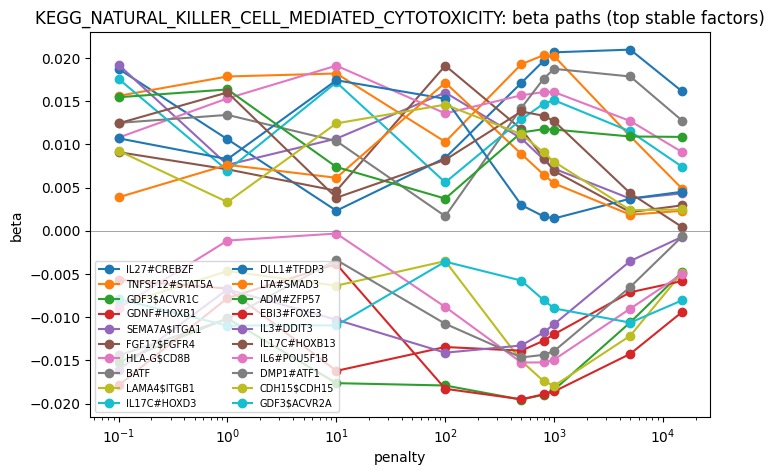

In [13]:
top = stable.sort_values('abs_max', ascending=False)['factor'].tail(20).tolist()
fig, ax = plt.subplots(figsize=(8, 5))
for f in top:
    d = sweep[sweep['factor'] == f].sort_values('penalty')
    ax.plot(d['penalty'], d['beta'], marker='o', label=f)
ax.set_xscale('log'); ax.axhline(0, color='gray', lw=0.5)
ax.set_xlabel('penalty'); ax.set_ylabel('beta'); ax.legend(fontsize=7, ncol=2)
ax.set_title(f'{TARGET}: beta paths (top stable factors)');